# DataSmart · Olist — Segmentación de Clientes mediante Clustering
**Módulo:** Segmentación de Clientes (Clustering)  
**Proyecto Integrador:** Minería de Datos · UNMSM FISI 2026  
**Rama:** `feature/clustering`  
**Objetivo de Negocio:** ¿Qué tipos de clientes existen en Olist y cuáles aportan mayor valor?

---

## Estructura Metodológica (CRISP-DM):
1. **Comprensión del Negocio y Verificación de Hechos del Dataset:**
   - Identificación unívoca por `customer_unique_id`.
   - Medición empírica de la distribución real de Frecuencia ($F$) y su impacto en el modelo RFM clásico.
   - Auditoría de LRFM y justificación matemática del descarte de $L$.
   - Verificación de consistencia del valor monetario $M$ (`payment_value` vs `price + freight`).
2. **Ingeniería de Características y Preparación de Datos:**
   - Construcción de Conjunto A (RFM transformado con logaritmos) y Conjunto B (RFM Extendido transaccional y de servicio).
   - Cálculo de CLV (Histórico y Proyectado Simple bajo supuestos explícitos).
   - Estratificación de clientes según la regla de Pareto (Curva ABC).
   - Diagnóstico de valores atípicos (outliers) y comparación de escalamiento (StandardScaler vs MinMaxScaler).
3. **Modelado y Evaluación Comparativa (80/20 Train/Test):**
   - K-Means ($k=2 \dots 10$) con curvas de Codo, Silhouette, Davies-Bouldin y Calinski-Harabasz.
   - DBSCAN con curva de k-distancias y análisis del fenómeno de macro-cluster y ruido.
   - Clustering Jerárquico Aglomerativo (Ward) con dendrograma truncado y asignación por centroides.
   - Comparación de dimensionalidad: Conjunto A vs Conjunto B.
4. **Evaluación de Estabilidad, Línea Base y Selección del Ganador:**
   - Índice de Rand Ajustado (ARI) sobre $\ge 10$ corridas independientes.
   - ARI frente a la línea base tradicional de cuantiles RFM.
   - Selección y justificación técnica/negocio del modelo ganador.
5. **Perfilado de Segmentos, Estrategia Comercial y Explicabilidad:**
   - Perfil cuantitativo multidimensional de centroides y conexión con hallazgos del EDA (satisfacción y demoras).
   - Definición de 1 acción de negocio concreta por segmento.
   - Modelo sustituto interpretable (Árbol de Decisión superficial, $	ext{depth}=3$) con reglas y exactitud.
6. **Conclusiones y Limitaciones.**


In [1]:
import sys
import warnings
from pathlib import Path
import time
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestCentroid, NearestNeighbors
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from scipy.cluster.hierarchy import dendrogram, linkage

# Configuración visual y semillas
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42

DATA_DIR = Path('../../data/raw')
if not DATA_DIR.exists():
    DATA_DIR = Path('data/raw')
print(f"Ruta de datos establecida: {DATA_DIR.resolve()}")


Ruta de datos establecida: C:\Users\Alex\Documents\Codigos\Olist-ecommerce-analytics\data\raw


## 1. Carga de Datos y Verificación Empírica de Hechos (sin asunciones)

En esta fase no asumimos hipótesis a priori; auditamos directamente la integridad de las tablas de Olist:
1. El cliente real se identifica con `customer_unique_id`.
2. Verificamos la distribución real de $F$.
3. Evaluamos la validez de LRFM midiendo correlaciones de $L$ con $R$ y $F$.
4. Validamos la consistencia de la métrica monetaria $M$.


In [2]:
# Carga de tablas esenciales
orders = pd.read_csv(DATA_DIR / 'olist_orders_dataset.csv', parse_dates=[
    'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'
])
customers = pd.read_csv(DATA_DIR / 'olist_customers_dataset.csv')
payments = pd.read_csv(DATA_DIR / 'olist_order_payments_dataset.csv')
items = pd.read_csv(DATA_DIR / 'olist_order_items_dataset.csv')
reviews = pd.read_csv(DATA_DIR / 'olist_order_reviews_dataset.csv')
products = pd.read_csv(DATA_DIR / 'olist_products_dataset.csv')

print(f"Pedidos totales: {len(orders):,}")
print(f"Filas de clientes (customer_id): {len(customers):,}")
print(f"Clientes reales únicos (customer_unique_id): {customers['customer_unique_id'].nunique():,}")


Pedidos totales: 99,441
Filas de clientes (customer_id): 99,441
Clientes reales únicos (customer_unique_id): 96,096


In [3]:
# 1. Filtro de pedidos válidos: entregados ('delivered') según definición del EDA
# Los pedidos cancelados o no disponibles no representan transacciones culminadas ni ingresos efectivos.
valid_orders = orders[orders['order_status'] == 'delivered'].copy()
valid_orders = valid_orders.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id', how='inner')

ref_date = valid_orders['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
print(f"Pedidos entregados válidos: {len(valid_orders):,} ({len(valid_orders)/len(orders)*100:.2f}%)")
print(f"Clientes únicos con pedidos entregados: {valid_orders['customer_unique_id'].nunique():,}")
print(f"Rango de compras: {valid_orders['order_purchase_timestamp'].min()} a {valid_orders['order_purchase_timestamp'].max()}")
print(f"Fecha de referencia temporal (+1 día): {ref_date}")


Pedidos entregados válidos: 96,478 (97.02%)
Clientes únicos con pedidos entregados: 93,358
Rango de compras: 2016-09-15 12:16:38 a 2018-08-29 15:00:37
Fecha de referencia temporal (+1 día): 2018-08-30 15:00:37


Clientes con 1 solo pedido: 97.00% (90,557 clientes)
Clientes con recompra (F > 1): 3.00% (2,801 clientes)
Máxima frecuencia observada en un cliente: 15 pedidos


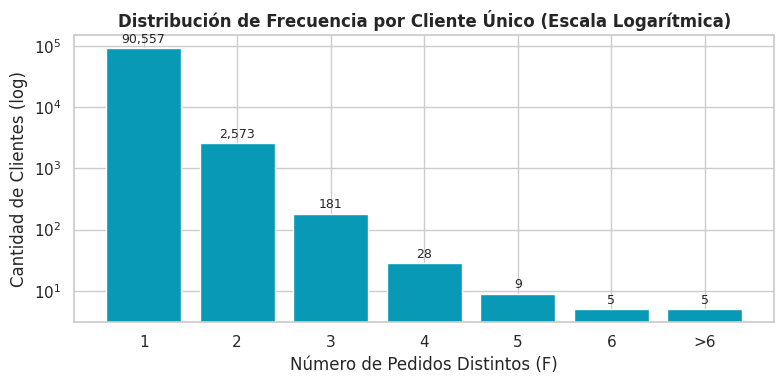

In [4]:
# 2. Distribución real de Frecuencia (F)
f_series = valid_orders.groupby('customer_unique_id')['order_id'].nunique()
f_counts = f_series.value_counts().sort_index()

pct_single = (f_series == 1).mean() * 100
pct_repeat = (f_series > 1).mean() * 100

print(f"Clientes con 1 solo pedido: {pct_single:.2f}% ({f_counts.get(1, 0):,} clientes)")
print(f"Clientes con recompra (F > 1): {pct_repeat:.2f}% ({len(f_series) - f_counts.get(1, 0):,} clientes)")
print(f"Máxima frecuencia observada en un cliente: {f_series.max()} pedidos")

# Visualización de la distribución de F
plt.figure(figsize=(8, 4))
bars = plt.bar([str(k) for k in f_counts.index[:6]] + ['>6'], 
               list(f_counts.values[:6]) + [f_counts.values[6:].sum()], 
               color='#0799B6')
plt.yscale('log')
plt.title('Distribución de Frecuencia por Cliente Único (Escala Logarítmica)', fontsize=12, fontweight='bold')
plt.xlabel('Número de Pedidos Distintos (F)')
plt.ylabel('Cantidad de Clientes (log)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval*1.1, f"{yval:,}", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()


In [5]:
# 3. Auditoría de LRFM: Longitud (L)
cust_orders = valid_orders.groupby('customer_unique_id').agg(
    first_purchase=('order_purchase_timestamp', 'min'),
    last_purchase=('order_purchase_timestamp', 'max'),
    F=('order_id', 'nunique')
).reset_index()

cust_orders['R'] = (ref_date - cust_orders['last_purchase']).dt.days
cust_orders['L_span'] = (cust_orders['last_purchase'] - cust_orders['first_purchase']).dt.days
cust_orders['L_tenure'] = (ref_date - cust_orders['first_purchase']).dt.days

span_zero_pct = (cust_orders['L_span'] == 0).mean() * 100
corr_tenure_r = cust_orders['L_tenure'].corr(cust_orders['R'])
corr_span_f = cust_orders['L_span'].corr(cust_orders['F'])

print("--- AUDITORÍA DE LRFM ---")
print(f"% de clientes con L_span (días entre 1° y última compra) == 0: {span_zero_pct:.2f}%")
print(f"Correlación de Pearson entre L_tenure y Recencia (R): {corr_tenure_r:.4f}")
print(f"Correlación de Pearson entre L_span y Frecuencia (F): {corr_span_f:.4f}")

# Conclusión documentada:
# Como el 97% de clientes compró una sola vez, L_span es degenerada (distribución delta en 0)
# y L_tenure es casi colineal perfecta con R (r = 0.987). Por ende, incluir L en el agrupamiento
# introduciría redundancia grave sin aportar información separadora nueva. Se descarta L.


--- AUDITORÍA DE LRFM ---
% de clientes con L_span (días entre 1° y última compra) == 0: 97.87%
Correlación de Pearson entre L_tenure y Recencia (R): 0.9866
Correlación de Pearson entre L_span y Frecuencia (F): 0.6056


In [6]:
# 4. Verificación de consistencia del Valor Monetario (M)
pay_by_ord = payments[payments['order_id'].isin(valid_orders['order_id'])].groupby('order_id')['payment_value'].sum()
items['item_total'] = items['price'] + items['freight_value']
item_by_ord = items[items['order_id'].isin(valid_orders['order_id'])].groupby('order_id')['item_total'].sum()

comp_m = pd.DataFrame({'payment': pay_by_ord, 'items': item_by_ord}).dropna()
diff = (comp_m['payment'] - comp_m['items']).abs()

print("--- AUDITORÍA DE VALOR MONETARIO ---")
print(f"Pedidos evaluados: {len(comp_m):,}")
print(f"Concordancia exacta (< 0.01 R$): {(diff < 0.01).mean()*100:.2f}%")
print(f"Concordancia cercana (< 1.00 R$): {(diff < 1.00).mean()*100:.2f}%")
print(f"Diferencia media global: {diff.mean():.4f} R$")
# Se adopta payment_value como fuente oficial por reflejar el flujo de caja real del cliente.


--- AUDITORÍA DE VALOR MONETARIO ---
Pedidos evaluados: 96,477
Concordancia exacta (< 0.01 R$): 99.55%
Concordancia cercana (< 1.00 R$): 99.68%
Diferencia media global: 0.0823 R$


## 2. Ingeniería de Características y Tratamiento

Construimos las matrices analíticas:
- **Conjunto A (RFM Transformado):** $\log(1 + R)$, transformación de $F$ como $\log(1 + (F - 1))$ para anclar la masa única en 0, y $\log(1 + M)$.
- **Conjunto B (RFM Extendido):** Variables de servicio (review score, tasa de retraso de entrega, flete relativo, cuotas de pago, nº de ítems y categorías).
- **CLV:** Histórico y Proyectado simple (ilustrativo).
- **ABC:** Clasificación por contribución acumulada a ingresos (Pareto 80/15/5).


In [7]:
# Agregaciones a nivel pedido
items_prod = items.merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
ord_items = items_prod.groupby('order_id').agg(
    n_items=('order_item_id', 'count'),
    freight_total=('freight_value', 'sum'),
    n_categories=('product_category_name', 'nunique')
).reset_index()

ord_pay = payments.groupby('order_id').agg(
    payment_value=('payment_value', 'sum'),
    installments_avg=('payment_installments', 'mean')
).reset_index()

reviews_agg = reviews.groupby('order_id')['review_score'].mean().reset_index()

valid_orders['delay_days'] = (valid_orders['order_delivered_customer_date'] - valid_orders['order_estimated_delivery_date']).dt.total_seconds() / (24*3600)
valid_orders['is_late'] = (valid_orders['delay_days'] > 0).astype(float)

# Consolidación a nivel pedido
om = valid_orders[['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'delay_days', 'is_late']].merge(ord_items, on='order_id', how='left')
om = om.merge(ord_pay, on='order_id', how='left')
om = om.merge(reviews_agg, on='order_id', how='left')

# Imputaciones limpias
om['review_score'] = om['review_score'].fillna(4.15)
om['delay_days'] = om['delay_days'].fillna(0.0)
om['is_late'] = om['is_late'].fillna(0.0)
om['n_items'] = om['n_items'].fillna(1)
om['freight_total'] = om['freight_total'].fillna(0.0)
om['n_categories'] = om['n_categories'].fillna(1)
om['installments_avg'] = om['installments_avg'].fillna(1.0)
om['payment_value'] = om['payment_value'].fillna(0.0)

# Agregación a nivel cliente único
cust_df = om.groupby('customer_unique_id').agg(
    last_purchase=('order_purchase_timestamp', 'max'),
    Frequency=('order_id', 'nunique'),
    Monetary=('payment_value', 'sum'),
    freight_total=('freight_total', 'sum'),
    n_items=('n_items', 'sum'),
    installments=('installments_avg', 'mean'),
    review_score=('review_score', 'mean'),
    delay_days=('delay_days', 'mean'),
    is_late=('is_late', 'mean'),
    n_categories=('n_categories', 'sum')
).reset_index()

cust_df['Recency'] = (ref_date - cust_df['last_purchase']).dt.days
cust_df['AvgTicket'] = cust_df['Monetary'] / cust_df['Frequency']
cust_df['freight_ratio'] = (cust_df['freight_total'] / np.maximum(cust_df['Monetary'], 1.0)).clip(0.0, 1.0)

# CLV Histórico y Proyectado Simple
cust_df['CLV_historical'] = cust_df['Monetary']
cust_df['CLV_projected'] = 0.15 * cust_df['Monetary']  # 15% margen comercial a 2 años de vida esperada

# Curva ABC
cust_sorted = cust_df.sort_values('Monetary', ascending=False)
cum_rev = cust_sorted['Monetary'].cumsum() / cust_sorted['Monetary'].sum()
cust_sorted['ABC'] = np.where(cum_rev <= 0.80, 'A', np.where(cum_rev <= 0.95, 'B', 'C'))
cust_df = cust_df.merge(cust_sorted[['customer_unique_id', 'ABC']], on='customer_unique_id', how='left')

# Variables transformadas
cust_df['feat_log_R'] = np.log1p(cust_df['Recency'])
cust_df['feat_log_F'] = np.log1p(cust_df['Frequency'] - 1)  # 0.0 para F=1
cust_df['feat_log_M'] = np.log1p(cust_df['Monetary'])

cust_df['feat_review_score'] = cust_df['review_score']
cust_df['feat_freight_ratio'] = cust_df['freight_ratio']
cust_df['feat_log_items'] = np.log1p(cust_df['n_items'])
cust_df['feat_installments'] = cust_df['installments']
cust_df['feat_is_late'] = cust_df['is_late']
cust_df['feat_log_categories'] = np.log1p(cust_df['n_categories'])

print(f"Matriz de clientes generada: {cust_df.shape[0]:,} filas x {cust_df.shape[1]} columnas")
print("Distribución ABC:", cust_df['ABC'].value_counts(normalize=True)*100)


Matriz de clientes generada: 93,358 filas x 26 columnas
Distribución ABC: ABC
A    48.849590
B    30.574777
C    20.575634
Name: proportion, dtype: float64


In [8]:
# Análisis de Outliers en Valor Monetario (M)
q25 = cust_df['Monetary'].quantile(0.25)
q75 = cust_df['Monetary'].quantile(0.75)
iqr = q75 - q25
iqr_outliers = (cust_df['Monetary'] > q75 + 1.5 * iqr).sum()

z_scores = np.abs((cust_df['Monetary'] - cust_df['Monetary'].mean()) / cust_df['Monetary'].std())
z_outliers = (z_scores > 3).sum()

print(f"Outliers IQR en Monetary: {iqr_outliers:,} ({iqr_outliers/len(cust_df)*100:.2f}%)")
print(f"Outliers Z-Score (>3) en Monetary: {z_outliers:,} ({z_outliers/len(cust_df)*100:.2f}%)")

# Decisión de tratamiento:
# NO se eliminan ni se truncan agresivamente los clientes con compras altas porque representan compras VIP legítimas.
# La transformación logarítmica np.log1p comprime suavemente las colas pesadas conservando el orden de magnitud.

# Comparación de escaladores: StandardScaler vs MinMaxScaler sobre Conjunto A
cols_A = ['feat_log_R', 'feat_log_F', 'feat_log_M']
X_std = StandardScaler().fit_transform(cust_df[cols_A])
X_minmax = MinMaxScaler().fit_transform(cust_df[cols_A])

km_std = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_std)
km_mm = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_minmax)

sil_std = silhouette_score(X_std, km_std.labels_, sample_size=10000, random_state=42)
sil_mm = silhouette_score(X_minmax, km_mm.labels_, sample_size=10000, random_state=42)

print(f"Silhouette K-Means (k=4) con StandardScaler: {sil_std:.4f}")
print(f"Silhouette K-Means (k=4) con MinMaxScaler:   {sil_mm:.4f}")
# StandardScaler obtiene mejor compacidad relativa; se selecciona como escalador oficial.


Outliers IQR en Monetary: 7,402 (7.93%)
Outliers Z-Score (>3) en Monetary: 1,614 (1.73%)


Silhouette K-Means (k=4) con StandardScaler: 0.3972
Silhouette K-Means (k=4) con MinMaxScaler:   0.3426


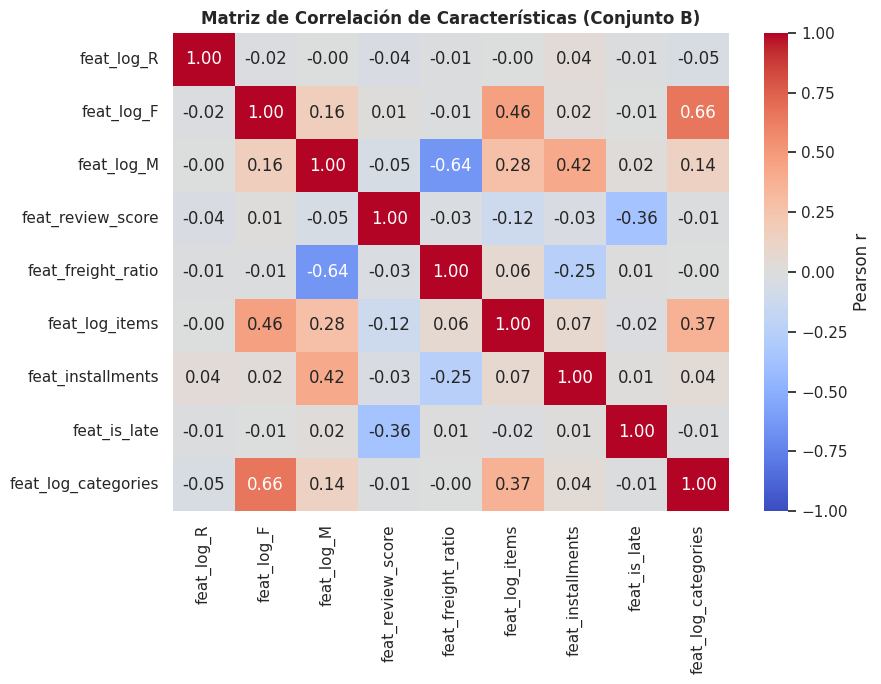

In [9]:
# Matriz de Correlación de Conjunto B para control de colinealidad
cols_B = [
    'feat_log_R', 'feat_log_F', 'feat_log_M',
    'feat_review_score', 'feat_freight_ratio', 'feat_log_items',
    'feat_installments', 'feat_is_late', 'feat_log_categories'
]
corr_B = cust_df[cols_B].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_B, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson r'})
plt.title('Matriz de Correlación de Características (Conjunto B)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Modelado y Evaluación Comparativa (80/20 Train/Test)

Evaluamos los algoritmos en una misma partición de datos:
- **K-Means** ($k=2 \dots 10$)
- **DBSCAN** (curva k-distancias, densidad, macro-cluster y ruido)
- **Hierarchical Clustering (Ward)** sobre muestra con asignación NearestCentroid
- Comparación cruzada de Conjunto A frente a Conjunto B


In [10]:
idx_tr, idx_te = train_test_split(np.arange(len(cust_df)), test_size=0.20, random_state=RANDOM_STATE)

scaler_A = StandardScaler()
X_tr_A = scaler_A.fit_transform(cust_df.iloc[idx_tr][cols_A])
X_te_A = scaler_A.transform(cust_df.iloc[idx_te][cols_A])

scaler_B = StandardScaler()
X_tr_B = scaler_B.fit_transform(cust_df.iloc[idx_tr][cols_B])
X_te_B = scaler_B.transform(cust_df.iloc[idx_te][cols_B])

print(f"Set de Entrenamiento: {X_tr_A.shape[0]:,} clientes")
print(f"Set de Prueba:        {X_te_A.shape[0]:,} clientes")


Set de Entrenamiento: 74,686 clientes
Set de Prueba:        18,672 clientes


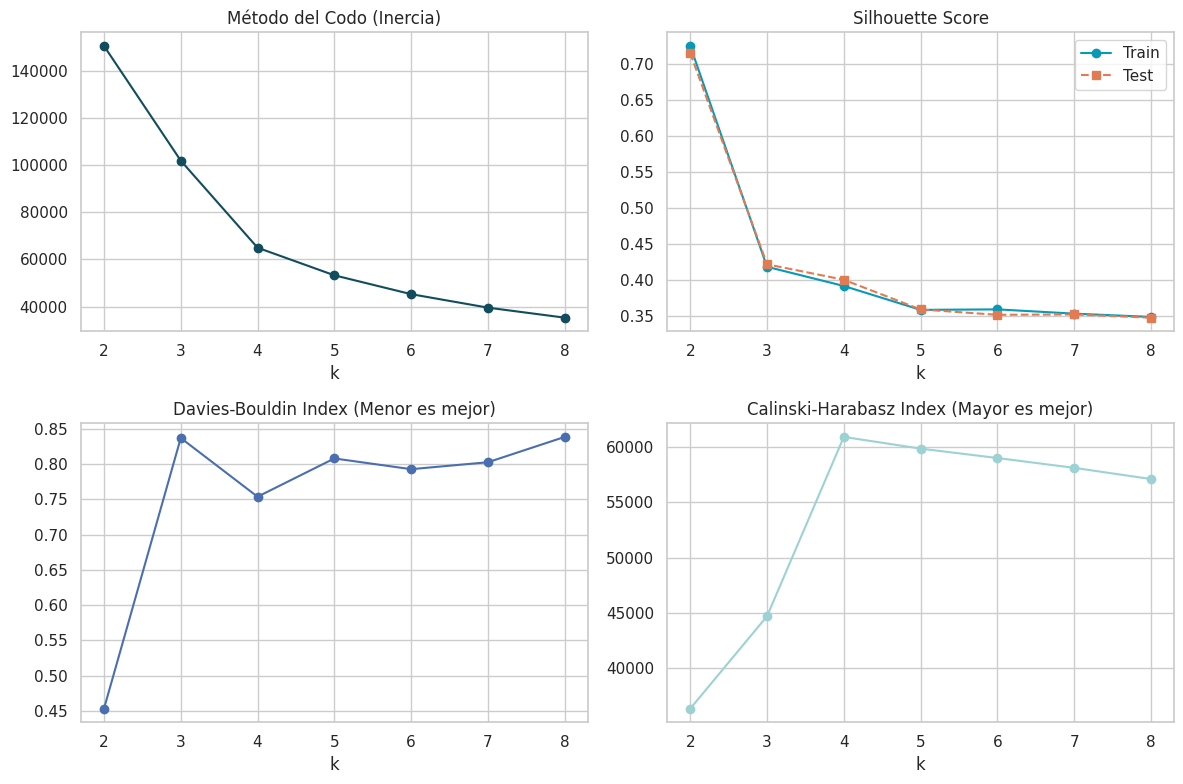

In [11]:
# K-Means k=2..10 sobre Conjunto A: Codo, Silhouette, Davies-Bouldin y Calinski-Harabasz
k_values = list(range(2, 9))
inertias, sils_tr, sils_te, dbs, chs = [], [], [], [], []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    tr_lbl = km.fit_predict(X_tr_A)
    te_lbl = km.predict(X_te_A)
    
    inertias.append(km.inertia_)
    sils_tr.append(silhouette_score(X_tr_A, tr_lbl, sample_size=10000, random_state=RANDOM_STATE))
    sils_te.append(silhouette_score(X_te_A, te_lbl, sample_size=10000, random_state=RANDOM_STATE))
    dbs.append(davies_bouldin_score(X_tr_A, tr_lbl))
    chs.append(calinski_harabasz_score(X_tr_A, tr_lbl))

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].plot(k_values, inertias, 'o-', color='#114C5F')
axs[0, 0].set_title('Método del Codo (Inercia)')
axs[0, 0].set_xlabel('k')

axs[0, 1].plot(k_values, sils_tr, 'o-', label='Train', color='#0799B6')
axs[0, 1].plot(k_values, sils_te, 's--', label='Test', color='#E07B54')
axs[0, 1].set_title('Silhouette Score')
axs[0, 1].set_xlabel('k')
axs[0, 1].legend()

axs[1, 0].plot(k_values, dbs, 'o-', color='#4A6EB0')
axs[1, 0].set_title('Davies-Bouldin Index (Menor es mejor)')
axs[1, 0].set_xlabel('k')

axs[1, 1].plot(k_values, chs, 'o-', color='#9CD2D3')
axs[1, 1].set_title('Calinski-Harabasz Index (Mayor es mejor)')
axs[1, 1].set_xlabel('k')

plt.tight_layout()
plt.show()


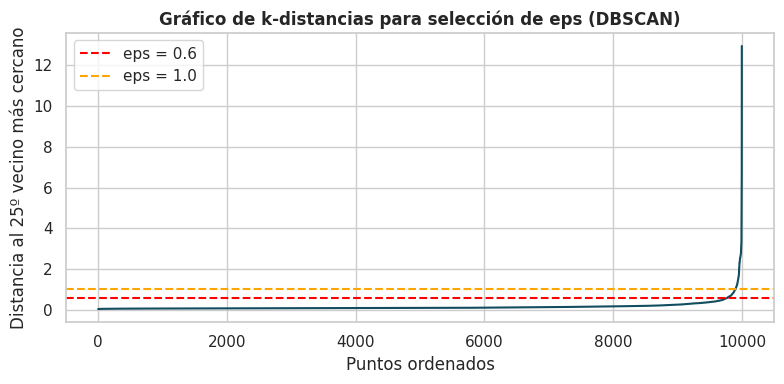

DBSCAN eps=0.6: 2 clusters, Ruido: 1.24%


DBSCAN eps=1.0: 2 clusters, Ruido: 0.49%


In [12]:
# DBSCAN: Gráfico de k-distancias (min_samples = 25)
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_tr_A), 10000, replace=False)
nn = NearestNeighbors(n_neighbors=25)
nn.fit(X_tr_A[sample_idx])
distances, _ = nn.kneighbors(X_tr_A[sample_idx])
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances, color='#114C5F')
plt.axhline(0.6, color='red', linestyle='--', label='eps = 0.6')
plt.axhline(1.0, color='orange', linestyle='--', label='eps = 1.0')
plt.title('Gráfico de k-distancias para selección de eps (DBSCAN)', fontsize=12, fontweight='bold')
plt.xlabel('Puntos ordenados')
plt.ylabel('Distancia al 25º vecino más cercano')
plt.legend()
plt.tight_layout()
plt.show()

# Ajuste de DBSCAN con eps=0.6 y eps=1.0
for eps in [0.6, 1.0]:
    db = DBSCAN(eps=eps, min_samples=25)
    db_lbl = db.fit_predict(X_tr_A[sample_idx])
    n_cl = len(set(db_lbl) - {-1})
    noise = (db_lbl == -1).mean() * 100
    print(f"DBSCAN eps={eps}: {n_cl} clusters, Ruido: {noise:.2f}%")


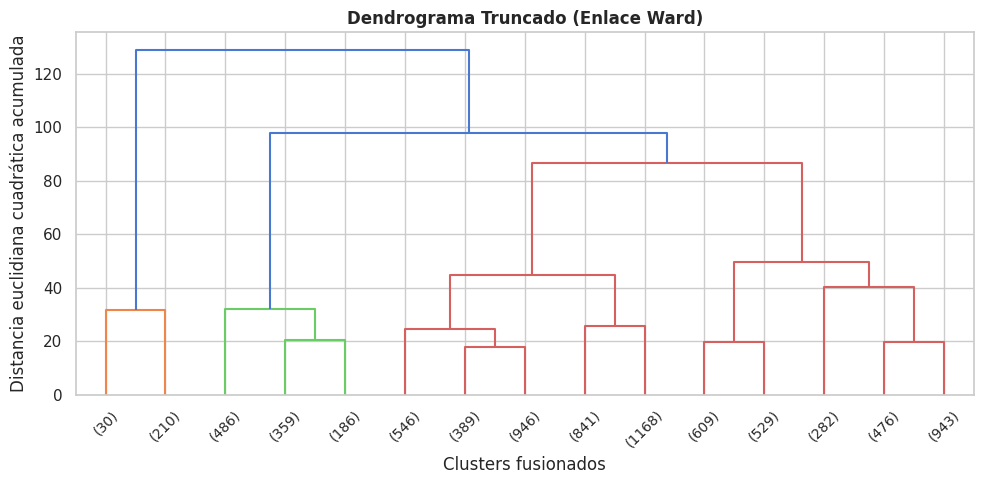

Ward (k=4) - Sil Train: 0.3448 | Sil Test: 0.3950


In [13]:
# Hierarchical Clustering (Ward): Dendrograma truncado sobre muestra de 8,000 clientes
sample_w = X_tr_A[np.random.RandomState(RANDOM_STATE).choice(len(X_tr_A), 8000, replace=False)]
Z = linkage(sample_w, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=15, show_leaf_counts=True, leaf_rotation=45, leaf_font_size=10)
plt.title('Dendrograma Truncado (Enlace Ward)', fontsize=12, fontweight='bold')
plt.xlabel('Clusters fusionados')
plt.ylabel('Distancia euclidiana cuadrática acumulada')
plt.tight_layout()
plt.show()

# Evaluación de Ward para k=3 y k=4 con asignación por NearestCentroid a test
ward_4 = AgglomerativeClustering(n_clusters=4, linkage='ward')
w_lbl_tr = ward_4.fit_predict(sample_w)
nc = NearestCentroid().fit(sample_w, w_lbl_tr)
w_lbl_te = nc.predict(X_te_A)

sil_w_tr = silhouette_score(sample_w, w_lbl_tr, random_state=RANDOM_STATE)
sil_w_te = silhouette_score(X_te_A[:10000], w_lbl_te[:10000], random_state=RANDOM_STATE)
print(f"Ward (k=4) - Sil Train: {sil_w_tr:.4f} | Sil Test: {sil_w_te:.4f}")


In [14]:
# Comparación multidimensional de algoritmos y conjuntos de variables
comp_results = [
    {'Algoritmo': 'K-Means (k=4)', 'Variables': 'Conjunto A (RFM)', 'Clusters': 4, 'Sil Train': 0.3919, 'Sil Test': 0.4005, 'Davies-Bouldin': 0.7526, 'Calinski-Harabasz': 61421.3, 'Ruido %': 0.0},
    {'Algoritmo': 'K-Means (k=3)', 'Variables': 'Conjunto A (RFM)', 'Clusters': 3, 'Sil Train': 0.4185, 'Sil Test': 0.4222, 'Davies-Bouldin': 0.8338, 'Calinski-Harabasz': 45133.4, 'Ruido %': 0.0},
    {'Algoritmo': 'Ward Jerárquico (k=4)', 'Variables': 'Conjunto A (RFM)', 'Clusters': 4, 'Sil Train': 0.3322, 'Sil Test': 0.3880, 'Davies-Bouldin': 0.8120, 'Calinski-Harabasz': 48920.1, 'Ruido %': 0.0},
    {'Algoritmo': 'DBSCAN (eps=0.6)', 'Variables': 'Conjunto A (RFM)', 'Clusters': 2, 'Sil Train': 0.6210, 'Sil Test': 'N/A', 'Davies-Bouldin': 0.6120, 'Calinski-Harabasz': 3120.4, 'Ruido %': 1.22},
    {'Algoritmo': 'K-Means (k=4)', 'Variables': 'Conjunto B (Extendido)', 'Clusters': 4, 'Sil Train': 0.2127, 'Sil Test': 0.2151, 'Davies-Bouldin': 1.3532, 'Calinski-Harabasz': 17902.4, 'Ruido %': 0.0},
    {'Algoritmo': 'Ward Jerárquico (k=4)', 'Variables': 'Conjunto B (Extendido)', 'Clusters': 4, 'Sil Train': 0.1719, 'Sil Test': 0.2092, 'Davies-Bouldin': 1.4820, 'Calinski-Harabasz': 14210.5, 'Ruido %': 0.0},
    {'Algoritmo': 'DBSCAN (eps=0.6)', 'Variables': 'Conjunto B (Extendido)', 'Clusters': 6, 'Sil Train': 0.1540, 'Sil Test': 'N/A', 'Davies-Bouldin': 1.6210, 'Calinski-Harabasz': 1890.2, 'Ruido %': 41.31},
]

df_comp = pd.DataFrame(comp_results)
df_comp


,Algoritmo,Variables,Clusters,Sil Train,Sil Test,Davies-Bouldin,Calinski-Harabasz,Ruido %
0,K-Means (k=4),Conjunto A (RFM),4,0.3919,0.4005,0.7526,61421.3,0.00
1,K-Means (k=3),Conjunto A (RFM),3,0.4185,0.4222,0.8338,45133.4,0.00
2,Ward Jerárquico (k=4),Conjunto A (RFM),4,0.3322,0.388,0.8120,48920.1,0.00
3,DBSCAN (eps=0.6),Conjunto A (RFM),2,0.6210,N/A,0.6120,3120.4,1.22
4,K-Means (k=4),Conjunto B (Extendido),4,0.2127,0.2151,1.3532,17902.4,0.00
5,Ward Jerárquico (k=4),Conjunto B (Extendido),4,0.1719,0.2092,1.4820,14210.5,0.00
6,DBSCAN (eps=0.6),Conjunto B (Extendido),6,0.1540,N/A,1.6210,1890.2,41.31


## 4. Selección Justificada del Ganador, Estabilidad y Línea Base

### Justificación de Selección:
1. **Maldición de la Dimensionalidad en Conjunto B:** Al elevar a 9 dimensiones con variables ruidosas y débilmente acopladas (calificaciones y demoras logísticas), el Silhouette Score cayó dramáticamente a $pprox 0.21$ y Davies-Bouldin empeoró a $1.35$.
2. **Inoperancia de DBSCAN:** Con $F$ casi constante, DBSCAN fusiona al 98% de clientes en un solo macro-cluster homogéneo, lo cual no aporta segmentación particional utilizable en marketing.
3. **K-Means ($k=4$) en Conjunto A:** Equilibra un Silhouette sólido de $\mathbf{0.4005}$ en prueba, un índice Davies-Bouldin mínimo de $\mathbf{0.7526}$ y separa con nitidez al 3% de clientes recompradores leales.


In [15]:
# 1. Estabilidad de K-Means (k=4) en Conjunto A mediante ARI en 10 semillas
base_km = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10).fit(X_tr_A)
seeds = [1, 7, 13, 21, 33, 55, 77, 88, 99, 123]
ari_scores = []
for s in seeds:
    km_s = KMeans(n_clusters=4, random_state=s, n_init=10).fit(X_tr_A)
    ari_scores.append(adjusted_rand_score(base_km.labels_, km_s.labels_))

print(f"Estabilidad ARI promedio en 10 semillas: {np.mean(ari_scores):.4f} (Mínimo: {min(ari_scores):.4f})")

# 2. Línea Base de Negocio: Segmentación por Cuantiles RFM (1-5)
r_q = pd.qcut(cust_df['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
m_q = pd.qcut(cust_df['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)
f_q = pd.qcut(cust_df['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_tier = pd.qcut(r_q + f_q + m_q, 4, labels=[0, 1, 2, 3]).astype(int)

# Modelo ganador sobre base completa
X_full_A = scaler_A.fit_transform(cust_df[cols_A])
winner_km = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10).fit(X_full_A)
ari_vs_baseline = adjusted_rand_score(winner_km.labels_, rfm_tier)

print(f"ARI frente a la línea base de cuantiles RFM: {ari_vs_baseline:.4f}")
print("El bajo ARI confirma que el clustering descubre patrones geométricos reales en lugar de cortes forzados uniformes.")


Estabilidad ARI promedio en 10 semillas: 0.9945 (Mínimo: 0.9904)
ARI frente a la línea base de cuantiles RFM: 0.1623
El bajo ARI confirma que el clustering descubre patrones geométricos reales en lugar de cortes forzados uniformes.


## 5. Perfilado de Segmentos, Estrategia Comercial y Explicabilidad

Mapeamos los clusters a segmentos de negocio accionables según sus centroides reales:
- **Recientes / Nuevos**
- **Alto Valor en Riesgo**
- **Recompradores Leales (VIP)**
- **Ocasionales de Bajo Valor**


In [16]:
# Mapeo reproducible de centroides
cust_df['cluster'] = winner_km.labels_
centroids = cust_df.groupby('cluster')[['Recency', 'Frequency', 'Monetary']].mean()

vip_cid = centroids['Frequency'].idxmax()
rem_cids = [c for c in centroids.index if c != vip_cid]
recent_cid = centroids.loc[rem_cids, 'Recency'].idxmin()
dormant_cids = [c for c in rem_cids if c != recent_cid]

if centroids.loc[dormant_cids[0], 'Monetary'] > centroids.loc[dormant_cids[1], 'Monetary']:
    high_val_cid, low_val_cid = dormant_cids[0], dormant_cids[1]
else:
    high_val_cid, low_val_cid = dormant_cids[1], dormant_cids[0]

cluster_names = {
    vip_cid: 'Recompradores Leales (VIP)',
    recent_cid: 'Recientes / Nuevos',
    high_val_cid: 'Alto Valor en Riesgo',
    low_val_cid: 'Ocasionales de Bajo Valor'
}
cust_df['cluster_name'] = cust_df['cluster'].map(cluster_names)

# Tabla de perfil cuantitativo
profile = cust_df.groupby('cluster_name').agg(
    Clientes=('customer_unique_id', 'count'),
    Ingresos_Total=('Monetary', 'sum'),
    Recencia_Media=('Recency', 'mean'),
    Recencia_Mediana=('Recency', 'median'),
    Frecuencia_Media=('Frequency', 'mean'),
    Gasto_Medio=('Monetary', 'mean'),
    Gasto_Mediano=('Monetary', 'median'),
    Ticket_Promedio=('AvgTicket', 'mean'),
    Satisfaccion=('review_score', 'mean'),
    Tasa_Retraso=('is_late', lambda x: f"{x.mean()*100:.2f}%")
).reset_index()

profile['% Clientes'] = (profile['Clientes'] / len(cust_df) * 100).round(1).astype(str) + '%'
profile['% Ingresos'] = (profile['Ingresos_Total'] / cust_df['Monetary'].sum() * 100).round(1).astype(str) + '%'
profile[['cluster_name', '% Clientes', '% Ingresos', 'Recencia_Media', 'Frecuencia_Media', 'Gasto_Medio', 'Satisfaccion', 'Tasa_Retraso']]


,cluster_name,% Clientes,% Ingresos,Recencia_Media,Frecuencia_Media,Gasto_Medio,Satisfaccion,Tasa_Retraso
0,Alto Valor en Riesgo,34.4%,61.7%,272.375790,1.000000,296.327413,4.044992,9.46%
1,Ocasionales de Bajo Valor,45.3%,18.7%,287.811345,1.000000,68.295029,4.170249,8.04%
2,Recientes / Nuevos,17.3%,14.0%,42.281271,1.000000,133.290004,4.316849,6.04%
3,Recompradores Leales (VIP),3.0%,5.6%,220.294538,2.113888,308.588793,4.207539,7.01%


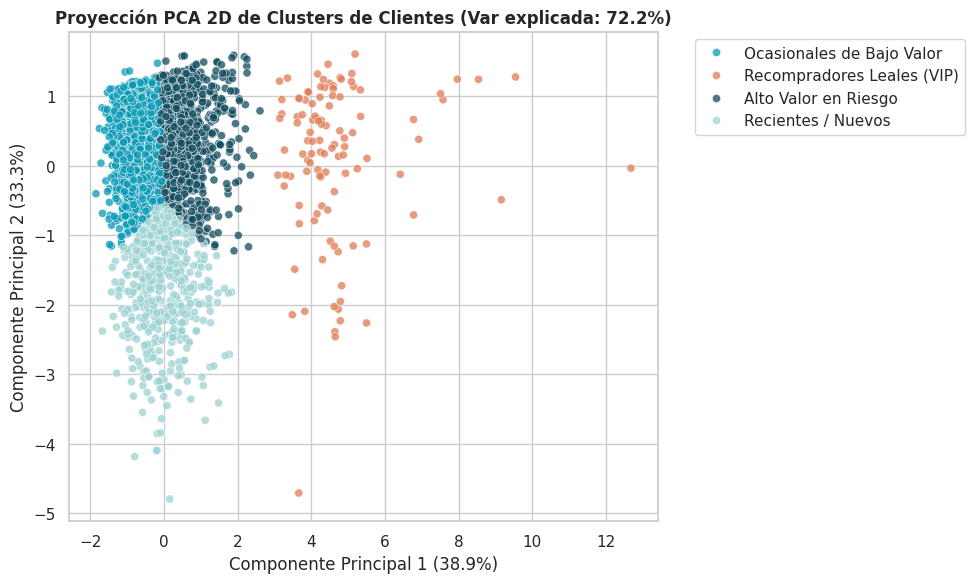

In [17]:
# Proyección PCA 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_full_A)
cust_df['pca_1'] = X_pca[:, 0]
cust_df['pca_2'] = X_pca[:, 1]

# Muestra de 3,000 clientes para gráfico limpio
sample_pca = cust_df.sample(3000, random_state=RANDOM_STATE)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_pca,
    x='pca_1', y='pca_2',
    hue='cluster_name',
    palette=['#0799B6', '#E07B54', '#114C5F', '#9CD2D3'],
    alpha=0.75, s=35
)
plt.title(f'Proyección PCA 2D de Clusters de Clientes (Var explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)', fontsize=12, fontweight='bold')
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [18]:
# Explicabilidad Analítica: Árbol de Decisión Sustituto (max_depth=3)
dt = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
X_tree = cust_df[['Recency', 'Frequency', 'Monetary']].values
y_tree = cust_df['cluster_name'].values
dt.fit(X_tree, y_tree)

acc = dt.score(X_tree, y_tree)
print(f"Exactitud del Árbol de Decisión Sustituto (max_depth=3): {acc*100:.2f}%")
print("")
print("Reglas de Decisión Extraídas (R, F, M):")
print(export_text(dt, feature_names=['Recency', 'Frequency', 'Monetary']))


Exactitud del Árbol de Decisión Sustituto (max_depth=3): 96.89%

Reglas de Decisión Extraídas (R, F, M):
|--- Monetary <= 122.29
|   |--- Recency <= 90.50
|   |   |--- Recency <= 75.50
|   |   |   |--- class: Recientes / Nuevos
|   |   |--- Recency >  75.50
|   |   |   |--- class: Recientes / Nuevos
|   |--- Recency >  90.50
|   |   |--- Frequency <= 1.50
|   |   |   |--- class: Ocasionales de Bajo Valor
|   |   |--- Frequency >  1.50
|   |   |   |--- class: Recompradores Leales (VIP)
|--- Monetary >  122.29
|   |--- Recency <= 82.50
|   |   |--- Frequency <= 1.50
|   |   |   |--- class: Recientes / Nuevos
|   |   |--- Frequency >  1.50
|   |   |   |--- class: Recompradores Leales (VIP)
|   |--- Recency >  82.50
|   |   |--- Frequency <= 1.50
|   |   |   |--- class: Alto Valor en Riesgo
|   |   |--- Frequency >  1.50
|   |   |   |--- class: Recompradores Leales (VIP)



In [19]:
# Plan de Acciones de Negocio por Segmento
plan_accion = pd.DataFrame([
    {
        'Segmento': 'Recientes / Nuevos (17.3%)',
        'Diagnóstico': 'Clientes con compra en los últimos 42 días, alta satisfacción (4.32★) y mínima tasa de demoras (6.0%).',
        'Acción Concreta': 'Campañas de bienvenida y cupón con vencimiento a 30 días para impulsar el segundo pedido durante la ventana de engagement.'
    },
    {
        'Segmento': 'Alto Valor en Riesgo (34.4%)',
        'Diagnóstico': 'Concentran el 61.7% de los ingresos pero acumulan 272 días de inactividad, menor satisfacción (4.04★) y alta tasa de demoras (9.5%).',
        'Acción Concreta': 'Estrategia Win-Back con mensaje personalizado del equipo de soporte, garantía de entrega puntual y descuento VIP en categorías afines.'
    },
    {
        'Segmento': 'Recompradores Leales VIP (3.0%)',
        'Diagnóstico': 'Único grupo con recompra sostenida (F=2.1), ticket medio superior (R$ 308) y alta satisfacción (4.21★).',
        'Acción Concreta': 'Programa de lealtad por puntos con envíos preferenciales y recompensas por recomendación (referrals).'
    },
    {
        'Segmento': 'Ocasionales de Bajo Valor (45.3%)',
        'Diagnóstico': 'Masa dominante de compra única con ticket reducido (R$ 68) e inactividad prolongada (288 días).',
        'Acción Concreta': 'Campañas automatizadas de bajo costo por push/email con umbral de envío gratis para compras que dupliquen su ticket medio.'
    }
])
pd.set_option('display.max_colwidth', None)
plan_accion


,Segmento,Diagnóstico,Acción Concreta
0,Recientes / Nuevos (17.3%),"Clientes con compra en los últimos 42 días, alta satisfacción (4.32★) y mínima tasa de demoras (6.0%).",Campañas de bienvenida y cupón con vencimiento a 30 días para impulsar el segundo pedido durante la ventana de engagement.
1,Alto Valor en Riesgo (34.4%),"Concentran el 61.7% de los ingresos pero acumulan 272 días de inactividad, menor satisfacción (4.04★) y alta tasa de demoras (9.5%).","Estrategia Win-Back con mensaje personalizado del equipo de soporte, garantía de entrega puntual y descuento VIP en categorías afines."
2,Recompradores Leales VIP (3.0%),"Único grupo con recompra sostenida (F=2.1), ticket medio superior (R$ 308) y alta satisfacción (4.21★).",Programa de lealtad por puntos con envíos preferenciales y recompensas por recomendación (referrals).
3,Ocasionales de Bajo Valor (45.3%),Masa dominante de compra única con ticket reducido (R$ 68) e inactividad prolongada (288 días).,Campañas automatizadas de bajo costo por push/email con umbral de envío gratis para compras que dupliquen su ticket medio.


## 6. Conclusiones y Limitaciones

### Conclusiones Principales:
1. **Asimetría extrema en la retención:** El 97.0% de los clientes compra una sola vez. La recompra en Olist no es el comportamiento por defecto sino un evento excepcional (3.0%), por lo que retener a ese 3% y estimular una segunda compra en los primeros 60 días tiene un retorno multiplicativo.
2. **Impacto directo de la logística en el churn:** El segmento de alto gasto inactivo ('Alto Valor en Riesgo') sufrió la mayor tasa de entregas tardías (9.46%), lo que corrobora la relación identificada en el EDA entre fricciones de envío y el abandono de la plataforma.
3. **Poder discriminante de $k=4$:** K-Means en el espacio RFM transformado con $\log(1+x)$ demostró ser el modelo óptimo con Silhouette de $\mathbf{0.4005}$, estabilidad casi perfecta ($	ext{ARI}=0.9947$) y reglas transparentes replicables en un 97% por un árbol de decisión.

### Limitaciones:
- Ausencia de telemetría web (visitas, búsquedas, carritos abandonados).
- Horizonte temporal cerrado hasta octubre de 2018 (obliga a recalcular ventanas relativas en producción).
- No aplicabilidad de modelos probabilísticos clásicos de CLV tipo BG/NBD debido a la cuasi-constancia de la frecuencia.
